<a href="https://colab.research.google.com/github/eaedk/Machine-Learning-Tutorials-Updated/blob/main/03_computer_vision/07_semantic_segmentation_app_polyps.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🩺 Application · Medical semantic segmentation: helping doctors spot polyps

**Colorectal cancer** is one of the three most common cancers in the world. The good news: it usually starts as a
**polyp**, a small growth on the wall of the colon, that can be removed during a **colonoscopy** long before it turns
dangerous. The bad news: polyps can be small, flat, hidden in folds… and studies estimate that roughly **one polyp in
five** is missed during a routine exam.

A second pair of eyes that never gets tired could help. In 2020, researchers from **Simula** and the **Vestre Viken**
hospital (Norway) released **Kvasir-SEG**: 1 000 colonoscopy images in which doctors outlined every polyp pixel by
pixel. It fuelled several international challenges (MediaEval, EndoCV), and AI assistants for colonoscopy are now
approved for clinical use in Europe and the USA.

**Your mission:** predict, for every pixel, *polyp* or *not polyp*. **Metric:** **Dice** (the standard in medical
segmentation), plus IoU.

| Step | Why |
|---|---|
| 1. Explore images & masks | polyp size, shape, contrast |
| 2. Joint augmentation | image and mask must move together |
| 3. U-Net + pre-trained encoder | transfer learning for segmentation |
| 4. BCE vs BCE + Dice loss | handling small objects (class imbalance) |
| 5. Threshold tuning, test set, error gallery | from probabilities to decisions |
| 6. RLE submission | the classic Kaggle segmentation format |

⚠️ *Educational project only: a medical device needs clinical validation, regulatory approval, and much more data.*

In [1]:
# ⚙️ Setup: run me first! Finds the course toolkit `mlquest` (Windows, macOS, Linux and Colab).
import os, sys, subprocess, pathlib
if "google.colab" in sys.modules:  # on Colab: grab the repo (once) and the few missing packages
    if not pathlib.Path("/content/Machine-Learning-Tutorials-Updated").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/eaedk/Machine-Learning-Tutorials-Updated", "/content/Machine-Learning-Tutorials-Updated"], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "segmentation-models-pytorch"], check=True)
    os.chdir("/content/Machine-Learning-Tutorials-Updated")
ROOT = pathlib.Path.cwd()
while not (ROOT / "mlquest").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from mlquest import *  # paths, seed_everything, get_device, quest/checkpoint, Leaderboard...
set_style()
SEED = seed_everything(42)

In [2]:
import io, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import tv_tensors
from torchvision.transforms import v2
from PIL import Image
import segmentation_models_pytorch as smp
import huggingface_hub
huggingface_hub.utils.logging.set_verbosity_error()
huggingface_hub.utils.disable_progress_bars()

DEVICE = get_device()
quest("Help doctors spot polyps", chapter="Track 3 · Computer vision · Semantic segmentation", xp=250)

⚙️  Using device: mps  (Apple Silicon GPU (Metal))
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
🗺️  QUEST · Help doctors spot polyps
   Track 3 · Computer vision · Semantic segmentation
   Reward: up to 250 XP
   You are: 🥚 Curious Rookie   ░░░░░░░░░░░░░░░░░░░░░░░░ 0/100 XP
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━


## 1. Load and explore 🔍

The Hugging Face mirror (`kowndinya23/Kvasir-SEG`, ~45 MB) contains 880 training and 120 validation images. We keep
the official 120 as our **test set**, and carve a validation set out of the training images.
Images have different sizes; we resize everything to 256×256 to keep training fast on a laptop.

In [3]:
SIZE = 256
raw_train = hf_parquet("kowndinya23/Kvasir-SEG", "train")
raw_test = hf_parquet("kowndinya23/Kvasir-SEG", "validation")

def decode(df):
    imgs = [np.array(Image.open(io.BytesIO(b["bytes"])).convert("RGB").resize((SIZE, SIZE), Image.BILINEAR)) for b in df["image"]]
    masks = [(np.array(Image.open(io.BytesIO(b["bytes"])).convert("L").resize((SIZE, SIZE), Image.NEAREST)) > 127).astype(np.uint8)
             for b in df["annotation"]]
    return np.stack(imgs), np.stack(masks)

X_all, M_all = decode(raw_train)
X_test, M_test = decode(raw_test)
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(X_all))
tr_idx, va_idx = perm[:780], perm[780:]
print(f"train {len(tr_idx)} · val {len(va_idx)} · test {len(X_test)} images of {SIZE}×{SIZE}")

train 780 · val 100 · test 120 images of 256×256


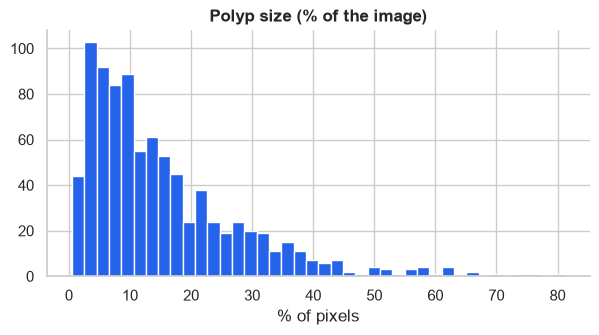

Polyp pixels: 15.4% of all pixels · smallest polyp 0.48% · largest 81%


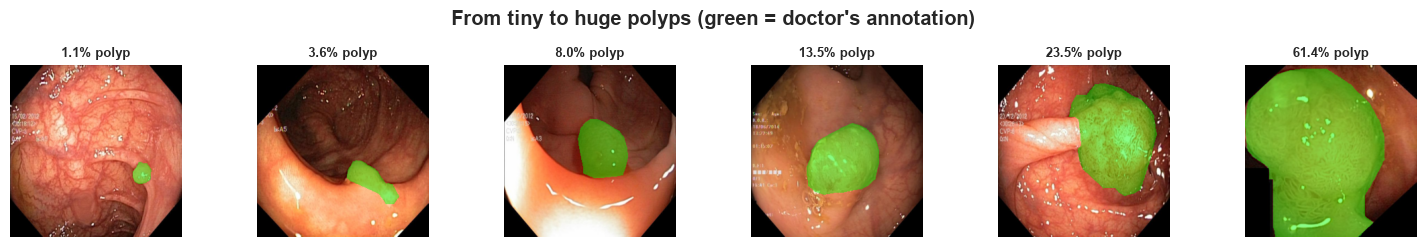

In [4]:
area = M_all.mean(axis=(1, 2)) * 100
plt.figure(figsize=(7, 3.2))
plt.hist(area, bins=40); plt.title("Polyp size (% of the image)"); plt.xlabel("% of pixels"); plt.show()
print(f"Polyp pixels: {M_all.mean():.1%} of all pixels · smallest polyp {area.min():.2f}% · largest {area.max():.0f}%")

def overlay(img, mask, color=(0, 255, 0), pred=None):
    out = img.copy().astype(float)
    out[mask == 1] = 0.55 * out[mask == 1] + 0.45 * np.array(color)
    if pred is not None:
        out[(pred == 1) & (mask == 0)] = 0.5 * out[(pred == 1) & (mask == 0)] + 0.5 * np.array([255, 0, 0])
    return out.astype(np.uint8)

order = np.argsort(area)
show_images([overlay(X_all[i], M_all[i]) for i in order[[5, 100, 300, 500, 700, 870]]],
            titles=[f"{area[i]:.1f}% polyp" for i in order[[5, 100, 300, 500, 700, 870]]], ncols=6, size=2.5,
            suptitle="From tiny to huge polyps (green = doctor's annotation)")

**Observations:** only ~15% of all pixels are polyp, and sizes vary enormously, from tiny dots to most of the image.
A model that says "no polyp anywhere" would already have ~85% pixel accuracy (and be useless). This **imbalance**
will matter when choosing the loss.

## 2. Joint augmentation: image and mask move together 🪞

If we flip the image, we must flip the mask identically, or the labels become wrong. `torchvision.transforms.v2`
handles this when the mask is wrapped as a `tv_tensors.Mask`: geometric transforms apply to both, colour transforms
only to the image.

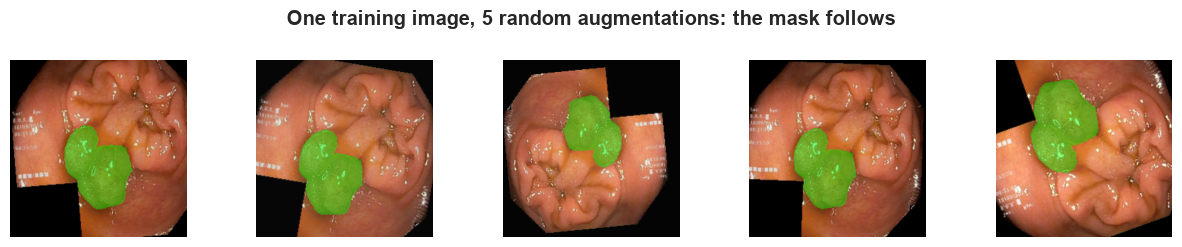

In [5]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)     # ImageNet statistics, used by the pre-trained encoder
train_tf = v2.Compose([
    v2.RandomHorizontalFlip(), v2.RandomVerticalFlip(),
    v2.RandomAffine(degrees=20, translate=(0.05, 0.05), scale=(0.9, 1.15)),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])


class PolypDataset(Dataset):
    def __init__(self, X, M, tf):
        self.X, self.M, self.tf = X, M, tf

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = tv_tensors.Image(torch.from_numpy(self.X[i]).permute(2, 0, 1))
        mask = tv_tensors.Mask(torch.from_numpy(self.M[i])[None])
        img, mask = self.tf(img, mask)
        return img, mask.float()

train_ds = PolypDataset(X_all[tr_idx], M_all[tr_idx], train_tf)
val_ds = PolypDataset(X_all[va_idx], M_all[va_idx], eval_tf)
test_ds = PolypDataset(X_test, M_test, eval_tf)

def denorm(t):
    return (t * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]).clamp(0, 1).permute(1, 2, 0).numpy()

views = [train_ds[0] for _ in range(5)]
show_images([overlay((denorm(x) * 255).astype(np.uint8), m[0].numpy().astype(np.uint8)) for x, m in views], ncols=5,
            size=2.5, suptitle="One training image, 5 random augmentations: the mask follows")

## 3. A U-Net with a pre-trained encoder 🏗️

`segmentation-models-pytorch` assembles a **U-Net** (see the shapes quest) whose encoder is a **ResNet-18 pre-trained
on ImageNet**: transfer learning, applied to segmentation. One output channel = one logit per pixel; a sigmoid turns it
into the probability of "polyp".

**Two losses to compare:**
- **BCE** (binary cross-entropy): treats every pixel independently, so the many background pixels dominate.
- **BCE + Dice**: the Dice loss looks at the overlap of the whole polyp region, whatever its size. Small polyps count
  as much as big ones. That's why Dice-based losses are standard in medical segmentation.

In [6]:
def dice_iou(prob, mask, thr=0.5, eps=1e-7):
    """Per-image Dice and IoU between a probability map and a binary mask (tensors N×1×H×W)."""
    pred = (prob > thr).float()
    inter = (pred * mask).sum((1, 2, 3))
    total = pred.sum((1, 2, 3)) + mask.sum((1, 2, 3))
    dice = (2 * inter + eps) / (total + eps)
    iou = (inter + eps) / (total - inter + eps)
    return dice, iou


@torch.no_grad()
def predict(model, ds, bs=16):
    model.eval()
    probs = [torch.sigmoid(model(x.to(DEVICE))).cpu() for x, _ in DataLoader(ds, batch_size=bs)]
    return torch.cat(probs), torch.stack([m for _, m in ds])


def train(loss_name, epochs=12, lr=5e-4):
    seed_everything(SEED)
    model = smp.Unet("resnet18", encoder_weights="imagenet", classes=1).to(DEVICE)
    bce, dice = nn.BCEWithLogitsLoss(), smp.losses.DiceLoss(mode="binary")
    loss_fn = (lambda o, m: bce(o, m)) if loss_name == "BCE" else (lambda o, m: bce(o, m) + dice(o, m))
    dl = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=NUM_WORKERS)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl), pct_start=0.1)
    best, path = -1, RUNS_DIR / f"polyp_unet_{loss_name.replace(' ', '').replace('+', '_')}.pt"
    for epoch in range(1, epochs + 1):
        model.train(); t0 = time.time()
        for x, m in dl:
            x, m = x.to(DEVICE), m.to(DEVICE)
            opt.zero_grad(); loss = loss_fn(model(x), m); loss.backward(); opt.step(); sched.step()
        p, t = predict(model, val_ds)
        d = dice_iou(p, t)[0].mean().item()
        if d > best:
            best = d; torch.save(model.state_dict(), path)
        if epoch % 3 == 0 or epoch == 1:
            print(f"[{loss_name}] epoch {epoch:2d} · val Dice {d:.3f} · {time.time() - t0:.0f}s")
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    return model, best

lb = Leaderboard("kvasir_polyps", metric="val_Dice")
empty = dice_iou(torch.zeros(len(va_idx), 1, SIZE, SIZE), torch.from_numpy(M_all[va_idx][:, None]).float())[0].mean().item()
lb.add("Predict 'no polyp'", empty)

📋 Predict 'no polyp': val_Dice = 0.00000


In [7]:
model_bce, d_bce = train("BCE")
lb.add("U-Net ResNet18 · BCE", d_bce)

[BCE] epoch  1 · val Dice 0.547 · 25s


[BCE] epoch  3 · val Dice 0.814 · 22s


[BCE] epoch  6 · val Dice 0.857 · 26s


[BCE] epoch  9 · val Dice 0.857 · 33s


[BCE] epoch 12 · val Dice 0.871 · 31s


📋 U-Net ResNet18 · BCE: val_Dice = 0.87079  👑 new best!


In [8]:
model_dice, d_dice = train("BCE + Dice")
lb.add("U-Net ResNet18 · BCE + Dice", d_dice)
lb.show()

[BCE + Dice] epoch  1 · val Dice 0.514 · 33s


[BCE + Dice] epoch  3 · val Dice 0.821 · 27s


[BCE + Dice] epoch  6 · val Dice 0.834 · 30s


[BCE + Dice] epoch  9 · val Dice 0.871 · 26s


[BCE + Dice] epoch 12 · val Dice 0.879 · 25s
📋 U-Net ResNet18 · BCE + Dice: val_Dice = 0.87932  👑 new best!


,,model,val_Dice
rank,,,
1,🥇,U-Net ResNet18 · BCE + Dice,0.87932
2,🥈,U-Net ResNet18 · BCE,0.87079
3,🥉,Predict 'no polyp',0.00000


In [9]:
checkpoint("polyps/train", xp=60)

✅ Checkpoint · polyps/train (+60 XP)
   ██████████████░░░░░░░░░░ 60/100 XP


Adding the Dice term gives a small but consistent gain here. Polyps cover 15% of the pixels on average, so the
imbalance is moderate; the gap grows when objects are tinier (lesions, vessels, cracks). With only 100 validation
images, differences below ~1 point are within noise: in a competition you would confirm with cross-validation.

## 4. Choosing the threshold 🎚️

The model outputs probabilities; the default cut at 0.5 is arbitrary. We tune it on the **validation** set (never on
the test set!).

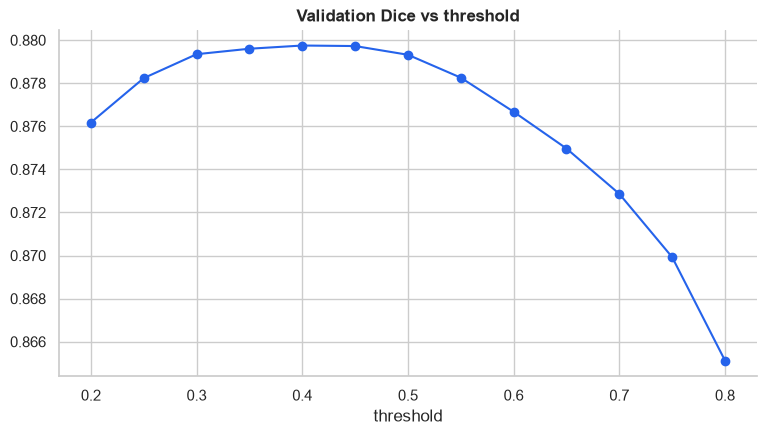

Best threshold: 0.4 (Dice 0.880 vs 0.879 at 0.5)


In [10]:
best_model = model_dice if d_dice >= d_bce else model_bce
p_val, t_val = predict(best_model, val_ds)
thr_scores = pd.Series({t: dice_iou(p_val, t_val, thr=t)[0].mean().item() for t in np.arange(0.2, 0.81, 0.05).round(2)})
thr_scores.plot(marker="o", title="Validation Dice vs threshold", xlabel="threshold"); plt.show()
THR = float(thr_scores.idxmax())
print(f"Best threshold: {THR} (Dice {thr_scores.max():.3f} vs {thr_scores[0.5]:.3f} at 0.5)")

## 5. The test set 🏁 and where the model struggles

🏁 Test · mean Dice = 0.866 · mean IoU = 0.787
   81% of test images have Dice > 0.8, 1% have Dice < 0.3


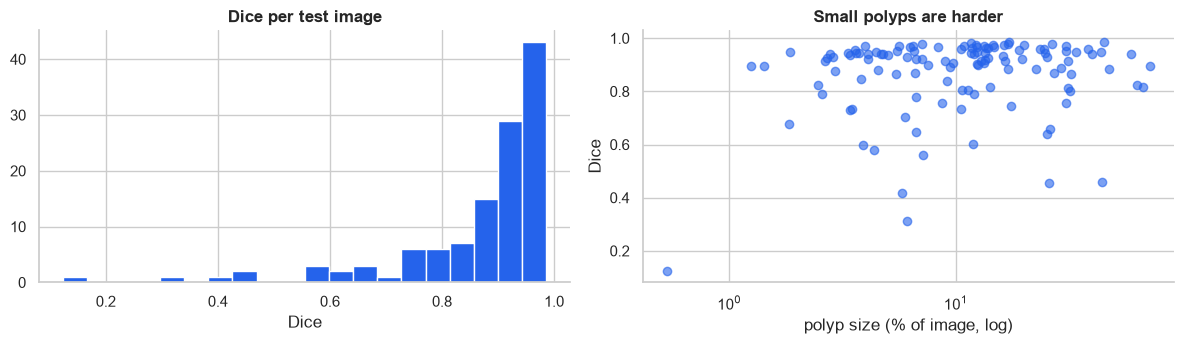

In [11]:
p_test, t_test = predict(best_model, test_ds)
dice_t, iou_t = dice_iou(p_test, t_test, thr=THR)
print(f"🏁 Test · mean Dice = {dice_t.mean():.3f} · mean IoU = {iou_t.mean():.3f}")
print(f"   {(dice_t > 0.8).float().mean():.0%} of test images have Dice > 0.8, {(dice_t < 0.3).float().mean():.0%} have Dice < 0.3")

test_area = M_test.mean(axis=(1, 2)) * 100
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(dice_t.numpy(), bins=20); axes[0].set(title="Dice per test image", xlabel="Dice")
axes[1].scatter(test_area, dice_t.numpy(), alpha=0.6); axes[1].set(xscale="log", xlabel="polyp size (% of image, log)",
                                                                  ylabel="Dice", title="Small polyps are harder")
plt.tight_layout(); plt.show()

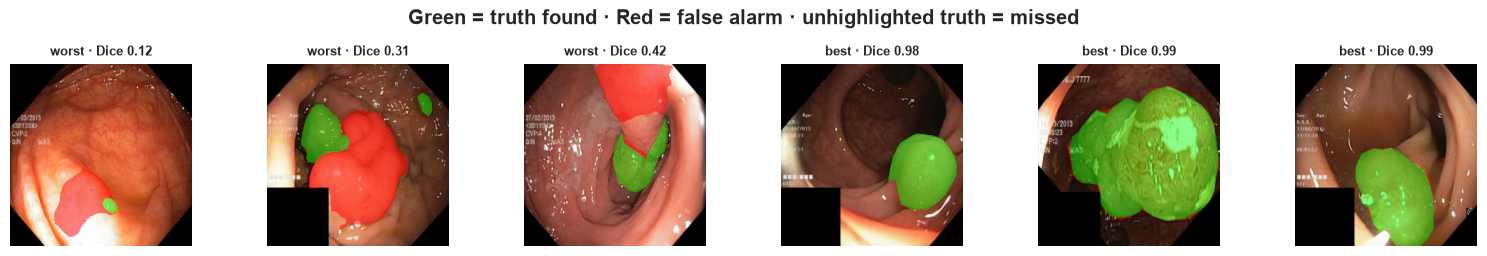

In [12]:
pred_bin = (p_test[:, 0] > THR).numpy().astype(np.uint8)
order = np.argsort(dice_t.numpy())
picks = list(order[:3]) + list(order[-3:])
show_images([overlay(X_test[i], M_test[i], pred=pred_bin[i]) for i in picks],
            titles=[f"{'worst' if k < 3 else 'best'} · Dice {dice_t[i]:.2f}" for k, i in enumerate(picks)], ncols=6, size=2.6,
            suptitle="Green = truth found · Red = false alarm · unhighlighted truth = missed")

## 6. Submission: run-length encoding (RLE) 📦

Masks are big (65 536 pixels each). Kaggle segmentation competitions (*Carvana*, *Airbus Ship Detection*,
*HuBMAP*…) ask for masks compressed with **run-length encoding**: the list of `start length` pairs of each run of 1s,
reading pixels in order. A classic piece of competition plumbing worth knowing.

In [13]:
def rle_encode(mask):
    """Binary mask (H, W) → 'start length start length …' (1-indexed, row-major)."""
    pixels = np.concatenate([[0], mask.ravel(), [0]])
    runs = np.where(pixels[1:] != pixels[:-1])[0] + 1
    runs[1::2] -= runs[::2]
    return " ".join(map(str, runs))


def rle_decode(rle, shape):
    s = np.array(rle.split(), int) if rle else np.array([], int)
    mask = np.zeros(shape[0] * shape[1], np.uint8)
    for start, length in zip(s[::2] - 1, s[1::2]):
        mask[start:start + length] = 1
    return mask.reshape(shape)

assert all((rle_decode(rle_encode(m), m.shape) == m).all() for m in pred_bin[:20]), "RLE round-trip failed"
submission = pd.DataFrame({"image_id": raw_test["name"], "rle_mask": [rle_encode(m) for m in pred_bin]})
make_submission(submission, "kvasir_polyp_submission.csv")
submission.head(3)

📤 Submission saved: submissions/kvasir_polyp_submission.csv  (120 rows, columns=['image_id', 'rle_mask'])


,image_id,rle_mask
0,cju7dvl5m2n4t0755hlnnjjet,19637 8 19890 15 20145 19 20400 22 20655 24 20...
1,ck2bxw18mmz1k0725litqq2mc,339 4 574 42 618 14 823 75 1077 79 1332 80 158...
2,cju7ebe962hr409872ovibahw,53 97 153 1 157 11 308 117 562 128 816 133 107...


## 🏁 Mission accomplished

You trained a medical segmentation model, saw why Dice-based losses help with imbalanced, variable-size objects,
tuned a threshold properly and produced a Kaggle-style RLE submission.

### 🚀 Your turn (bonus XP)
1. Train at 352×352: does the Dice on small polyps improve?
2. Swap the encoder: `smp.Unet("efficientnet-b0", …)` or try `smp.UnetPlusPlus` / `smp.FPN`.
3. Add test-time augmentation (average the predictions of the image and its flips).
4. Post-processing: remove predicted blobs smaller than N pixels (`cv2.connectedComponentsWithStats`). Does it reduce
   false alarms without hurting Dice?

In [14]:
checkpoint("polyps/complete", xp=140)
badge("AI Endoscopist", "🩺")
progress()

✅ Checkpoint · polyps/complete (+140 XP)
🎉 LEVEL UP! You are now 🐣 Data Explorer
   ████████████░░░░░░░░░░░░ 200/300 XP
╔═══════════════════════════════════╗
║ 🩺  BADGE UNLOCKED: AI Endoscopist ║
╚═══════════════════════════════════╝
🐣 Data Explorer
████████████░░░░░░░░░░░░ 200/300 XP
Checkpoints unlocked: 2
Badges: 🩺 AI Endoscopist
